# Taller 3 — APIs Públicas, MongoDB y EDA

**Curso:** Bases de Datos para Ciencia de Datos — **Docente:** Miguel Ramos García  
**Estudiante:** Ingrid Yohana Orrego García 

**API utilizada:** [Rick and Morty API](https://rickandmortyapi.com) — endpoint `/api/character`

Este notebook corresponde a la **Fase 3** del taller. El flujo completo es:

1. **Extracción:** `ingesta.py` descarga todos los personajes de la API (más de 800).
2. **Almacenamiento RAW:** el mismo script los guarda sin modificar en MongoDB (`taller3_db.raw_data`), usando el `id` de la API como `_id`.
3. **Procesamiento y EDA (este notebook):** se leen los datos desde MongoDB, se seleccionan las variables relevantes, se limpian y se analizan con estadísticas y gráficos.

## 1. Importación de librerías

- `pandas`: manipulación del DataFrame.
- `matplotlib`: gráficos.
- `pymongo`: conexión a MongoDB.
- `pprint`: mostrar un documento JSON de forma legible.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pymongo import MongoClient
from pprint import pprint

pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 100

## 2. Conexión a MongoDB

Nos conectamos a la base `taller3_db` y a la colección `raw_data` que llenó `ingesta.py`.
Verificamos que haya **al menos 100 documentos**.

> Si usas MongoDB Atlas, reemplaza `MONGO_URI` por tu cadena de conexión.

In [2]:
MONGO_URI = "mongodb://localhost:27017/"

client = MongoClient(MONGO_URI)
coleccion = client["taller3_db"]["raw_data"]

total_docs = coleccion.count_documents({})
print(f"Documentos en taller3_db.raw_data: {total_docs}")
print("¿Cumple el mínimo de 100 registros?", total_docs >= 100)

Documentos en taller3_db.raw_data: 826
¿Cumple el mínimo de 100 registros? True


### 2.1 Estructura de un documento crudo

Mostramos un documento tal como quedó guardado. Se observa que:
- `_id` es igual al `id` de la API (esto evita duplicados).
- `origin` y `location` son **diccionarios anidados**.
- `episode` es una **lista** de URLs (una por cada episodio en que aparece el personaje).

In [3]:
pprint(coleccion.find_one())

{'_id': 1,
 'created': '2017-11-04T18:48:46.250Z',
 'episode': ['https://rickandmortyapi.com/api/episode/1',
             'https://rickandmortyapi.com/api/episode/2',
             'https://rickandmortyapi.com/api/episode/3',
             'https://rickandmortyapi.com/api/episode/4',
             'https://rickandmortyapi.com/api/episode/5',
             'https://rickandmortyapi.com/api/episode/6',
             'https://rickandmortyapi.com/api/episode/7',
             'https://rickandmortyapi.com/api/episode/8',
             'https://rickandmortyapi.com/api/episode/9',
             'https://rickandmortyapi.com/api/episode/10',
             'https://rickandmortyapi.com/api/episode/11',
             'https://rickandmortyapi.com/api/episode/12',
             'https://rickandmortyapi.com/api/episode/13',
             'https://rickandmortyapi.com/api/episode/14',
             'https://rickandmortyapi.com/api/episode/15',
             'https://rickandmortyapi.com/api/episode/16',
             '

## 3. Selección de variables

Leemos la colección usando una **proyección** de MongoDB (solo traemos los campos que necesitamos) y construimos un DataFrame con **7 variables + el id**:

| Columna | Campo en el JSON | Descripción |
|---|---|---|
| `id` | `_id` | Identificador del personaje en la API |
| `nombre` | `name` | Nombre del personaje |
| `estado` | `status` | Vivo (*Alive*), muerto (*Dead*) o desconocido (*unknown*) |
| `especie` | `species` | Especie (Human, Alien, Robot, ...) |
| `genero` | `gender` | Male, Female, Genderless o unknown |
| `origen` | `origin.name` | Lugar de origen (campo anidado) |
| `ubicacion` | `location.name` | Última ubicación conocida (campo anidado) |
| `num_episodios` | `len(episode)` | Variable numérica derivada: cantidad de episodios en que aparece |

Se descartan campos como `image`, `url` o `created`, que no aportan al análisis.

In [4]:
proyeccion = {
    "_id": 1, "name": 1, "status": 1, "species": 1, "gender": 1,
    "origin.name": 1, "location.name": 1, "episode": 1,
}
documentos = list(coleccion.find({}, proyeccion))

registros = []
for doc in documentos:
    registros.append({
        "id": doc["_id"],
        "nombre": doc.get("name"),
        "estado": doc.get("status"),
        "especie": doc.get("species"),
        "genero": doc.get("gender"),
        "origen": (doc.get("origin") or {}).get("name"),
        "ubicacion": (doc.get("location") or {}).get("name"),
        "num_episodios": len(doc.get("episode") or []),
    })

df = pd.DataFrame(registros).sort_values("id").reset_index(drop=True)
print(f"DataFrame creado con {df.shape[0]} filas y {df.shape[1]} columnas")

DataFrame creado con 826 filas y 8 columnas


## 4. Inspección básica (punto A)

### 4.1 Primeras filas

In [5]:
df.head(10)

,id,nombre,estado,especie,genero,origen,ubicacion,num_episodios
0,1,Rick Sanchez,Alive,Human,Male,Earth (C-137),Citadel of Ricks,51
1,2,Morty Smith,Alive,Human,Male,unknown,Citadel of Ricks,51
2,3,Summer Smith,Alive,Human,Female,Earth (Replacement Dimension),Earth (Replacement Dimension),42
3,4,Beth Smith,Alive,Human,Female,Earth (Replacement Dimension),Earth (Replacement Dimension),42
4,5,Jerry Smith,Alive,Human,Male,Earth (Replacement Dimension),Earth (Replacement Dimension),39
5,6,Abadango Cluster Princess,Alive,Alien,Female,Abadango,Abadango,1
6,7,Abradolf Lincler,unknown,Human,Male,Earth (Replacement Dimension),Testicle Monster Dimension,2
7,8,Adjudicator Rick,Dead,Human,Male,unknown,Citadel of Ricks,1
8,9,Agency Director,Dead,Human,Male,Earth (Replacement Dimension),Earth (Replacement Dimension),1
9,10,Alan Rails,Dead,Human,Male,unknown,Worldender's lair,1


### 4.2 Tipos de datos

`info()` muestra el tipo de cada columna y cuántos valores no nulos tiene.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 826 entries, 0 to 825
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id             826 non-null    int64
 1   nombre         826 non-null    str  
 2   estado         826 non-null    str  
 3   especie        826 non-null    str  
 4   genero         826 non-null    str  
 5   origen         826 non-null    str  
 6   ubicacion      826 non-null    str  
 7   num_episodios  826 non-null    int64
dtypes: int64(2), str(6)
memory usage: 51.8 KB


### 4.3 Verificación de nulos

Contamos los valores nulos de cada columna. Además, esta API **no usa `null`** para la información faltante, sino el texto `"unknown"`, así que también contamos esos valores para tener una idea real de los datos faltantes.

In [7]:
resumen_faltantes = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "valores 'unknown'": (df == "unknown").sum(),
})
resumen_faltantes

,nulos,valores 'unknown'
id,0,0
nombre,0,0
estado,0,100
especie,0,13
genero,0,49
origen,0,300
ubicacion,0,21
num_episodios,0,0


### 4.4 Limpieza

- Verificamos que no haya personajes duplicados (gracias al `_id` no debería haberlos).
- Convertimos las variables categóricas (`estado`, `especie`, `genero`) al tipo `category`, que es más eficiente y adecuado para conteos.
- Los valores `"unknown"` **se conservan** como una categoría propia, porque representan información real de la API (personajes cuyo estado u origen se desconoce en la serie).

In [8]:
print("IDs duplicados:", df["id"].duplicated().sum())

for columna in ["estado", "especie", "genero"]:
    df[columna] = df[columna].astype("category")

df.dtypes

IDs duplicados: 0


id                  int64
nombre                str
estado           category
especie          category
genero           category
origen                str
ubicacion             str
num_episodios       int64
dtype: object

### 4.5 Estadística descriptiva de la variable numérica

In [9]:
df["num_episodios"].describe().round(2)

count    826.00
mean       1.53
std        3.56
min        1.00
25%        1.00
50%        1.00
75%        1.00
max       51.00
Name: num_episodios, dtype: float64

## 5. Insights numéricos (punto B)

### Insight 1 — ¿Cuántos personajes están vivos, muertos o en estado desconocido?

In [10]:
conteo_estado = df["estado"].value_counts()
porc_estado = df["estado"].value_counts(normalize=True).mul(100).round(1)

tabla_estado = pd.DataFrame({"personajes": conteo_estado, "porcentaje (%)": porc_estado})
tabla_estado

,personajes,porcentaje (%)
estado,,
Alive,439,53.1
Dead,287,34.7
unknown,100,12.1


### Insight 2 — ¿Qué personaje aparece en más episodios?

Usamos `nlargest` para ver los 5 personajes con más apariciones.

In [11]:
top_episodios = df.nlargest(5, "num_episodios")[["nombre", "especie", "num_episodios"]]
personaje_top = top_episodios.iloc[0]
print(f"El personaje que aparece en más episodios es {personaje_top['nombre']} "
      f"con {personaje_top['num_episodios']} episodios.")
top_episodios

El personaje que aparece en más episodios es Rick Sanchez con 51 episodios.


,nombre,especie,num_episodios
0,Rick Sanchez,Human,51
1,Morty Smith,Human,51
2,Summer Smith,Human,42
3,Beth Smith,Human,42
4,Jerry Smith,Human,39


### Insight 3 — ¿En cuántos episodios aparece un personaje en promedio?

Comparamos media y mediana, y calculamos qué porcentaje de personajes aparece en **un solo episodio**.

In [12]:
media_ep = df["num_episodios"].mean()
mediana_ep = df["num_episodios"].median()
porc_un_episodio = (df["num_episodios"] == 1).mean() * 100

print(f"Promedio de episodios por personaje: {media_ep:.2f}")
print(f"Mediana de episodios por personaje: {mediana_ep:.0f}")
print(f"Personajes que aparecen en un solo episodio: {porc_un_episodio:.1f}%")

Promedio de episodios por personaje: 1.53
Mediana de episodios por personaje: 1
Personajes que aparecen en un solo episodio: 88.0%


### Insight 4 — ¿Cuál es la especie más común?

In [13]:
conteo_especie = df["especie"].value_counts()
especie_top = conteo_especie.index[0]
porc_especie_top = conteo_especie.iloc[0] / len(df) * 100

print(f"Número de especies distintas: {df['especie'].nunique()}")
print(f"La especie más común es {especie_top} con {conteo_especie.iloc[0]} personajes "
      f"({porc_especie_top:.1f}% del total).")

Número de especies distintas: 10
La especie más común es Human con 366 personajes (44.3% del total).


### Insight 5 — ¿Cuál es el lugar de origen más frecuente?

Excluimos `"unknown"` para encontrar el origen conocido más común, y aparte calculamos qué porcentaje de personajes tiene origen desconocido.

In [14]:
origenes_conocidos = df.loc[df["origen"] != "unknown", "origen"].value_counts()
origen_top = origenes_conocidos.index[0]
porc_origen_desconocido = (df["origen"] == "unknown").mean() * 100

print(f"El origen conocido más frecuente es '{origen_top}' "
      f"con {origenes_conocidos.iloc[0]} personajes.")
print(f"El {porc_origen_desconocido:.1f}% de los personajes tiene origen desconocido.")

El origen conocido más frecuente es 'Earth (Replacement Dimension)' con 155 personajes.
El 36.3% de los personajes tiene origen desconocido.


### Resumen de los 5 insights

Esta celda reúne los 5 datos relevantes calculados arriba.

In [15]:
vivos = conteo_estado.get("Alive", 0)
muertos = conteo_estado.get("Dead", 0)
desconocidos = conteo_estado.get("unknown", 0)

insights = [
    f"De {len(df)} personajes, {vivos} están vivos ({porc_estado.get('Alive', 0)}%), "
    f"{muertos} muertos ({porc_estado.get('Dead', 0)}%) y {desconocidos} en estado desconocido.",
    f"El personaje que aparece en más episodios es {personaje_top['nombre']} "
    f"({personaje_top['num_episodios']} episodios).",
    f"Un personaje aparece en promedio en {media_ep:.2f} episodios (mediana = {mediana_ep:.0f}); "
    f"el {porc_un_episodio:.1f}% aparece en un solo episodio.",
    f"La especie más común es {especie_top}, con el {porc_especie_top:.1f}% de los personajes.",
    f"El origen conocido más frecuente es '{origen_top}' ({origenes_conocidos.iloc[0]} personajes), "
    f"y el {porc_origen_desconocido:.1f}% tiene origen desconocido.",
]

for i, texto in enumerate(insights, start=1):
    print(f"{i}. {texto}")

1. De 826 personajes, 439 están vivos (53.1%), 287 muertos (34.7%) y 100 en estado desconocido.
2. El personaje que aparece en más episodios es Rick Sanchez (51 episodios).
3. Un personaje aparece en promedio en 1.53 episodios (mediana = 1); el 88.0% aparece en un solo episodio.
4. La especie más común es Human, con el 44.3% de los personajes.
5. El origen conocido más frecuente es 'Earth (Replacement Dimension)' (155 personajes), y el 36.3% tiene origen desconocido.


## 6. Visualización (punto C)

### Gráfico 1 (obligatorio) — Gráfico de torta: proporción de personajes por género

Se muestra el porcentaje dentro de cada porción y la leyenda incluye la cantidad absoluta para que sea legible incluso en las porciones pequeñas.

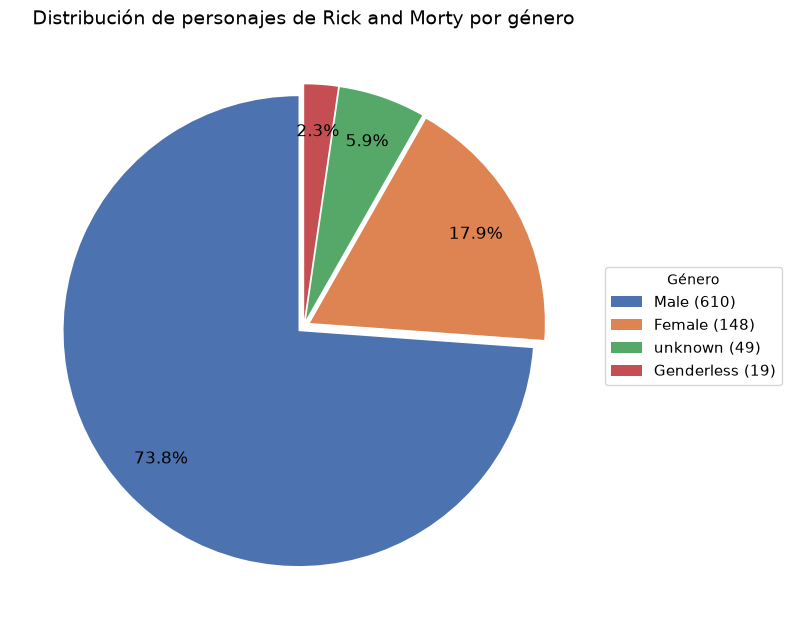

In [16]:
conteo_genero = df["genero"].value_counts()

fig, ax = plt.subplots(figsize=(8, 8))
porciones, _, _ = ax.pie(
    conteo_genero,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.8,
    explode=[0.03] * len(conteo_genero),
    colors=["#4C72B0", "#DD8452", "#55A868", "#C44E52"][: len(conteo_genero)],
    textprops={"fontsize": 12},
)
ax.legend(
    porciones,
    [f"{genero} ({cantidad})" for genero, cantidad in conteo_genero.items()],
    title="Género",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=11,
)
ax.set_title("Distribución de personajes de Rick and Morty por género", fontsize=14)
plt.tight_layout()
plt.show()

### Gráfico 2 — Barras horizontales: Top 10 especies con más personajes

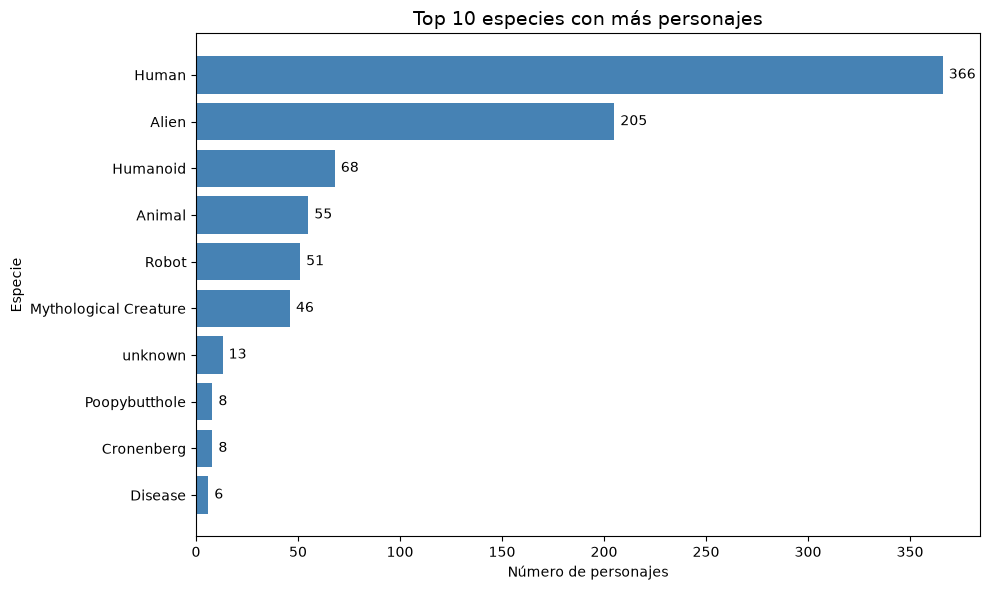

In [17]:
top_especies = df["especie"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_especies.index.astype(str), top_especies.values, color="steelblue")
for i, valor in enumerate(top_especies.values):
    ax.text(valor + 3, i, str(valor), va="center")

ax.set_title("Top 10 especies con más personajes", fontsize=14)
ax.set_xlabel("Número de personajes")
ax.set_ylabel("Especie")
plt.tight_layout()
plt.show()

### Gráfico 3 — Histograma: distribución del número de episodios por personaje

La línea roja marca el promedio. Permite ver que la mayoría de personajes aparece en muy pocos episodios, mientras que unos pocos (los protagonistas) aparecen en casi todos.

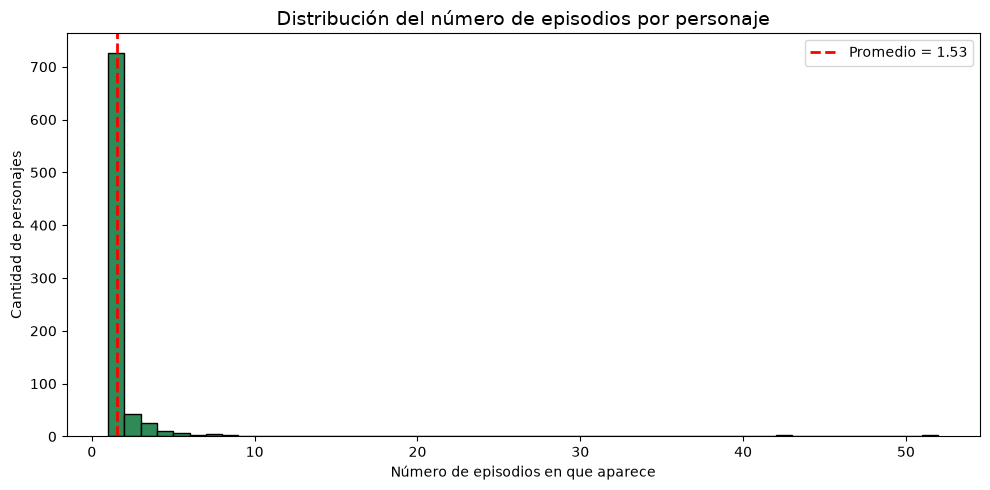

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(
    df["num_episodios"],
    bins=range(1, df["num_episodios"].max() + 2),
    color="seagreen",
    edgecolor="black",
)
ax.axvline(media_ep, color="red", linestyle="--", linewidth=2, label=f"Promedio = {media_ep:.2f}")

ax.set_title("Distribución del número de episodios por personaje", fontsize=14)
ax.set_xlabel("Número de episodios en que aparece")
ax.set_ylabel("Cantidad de personajes")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Conclusiones

A partir del análisis de los **826 personajes** descargados de la API de Rick and Morty y almacenados en MongoDB, se encontró lo siguiente:

1. **Estado de los personajes:** un poco más de la mitad sigue con vida (439 personajes, 53.1%), pero una proporción alta ha muerto (287 personajes, 34.7%). Esto refleja el tono de la serie, donde la muerte de personajes es frecuente. Además, 100 personajes tienen estado desconocido.

2. **Concentración en pocos personajes:** Rick Sanchez es el personaje que aparece en más episodios (51), mientras que el promedio por personaje es de apenas 1.53 episodios y la mediana es 1. El 88% de los personajes aparece en un solo episodio. Es decir, la serie tiene un núcleo muy pequeño de protagonistas y una gran cantidad de personajes que aparecen una sola vez. El histograma lo confirma: casi todos los datos se acumulan a la izquierda, con unos pocos valores extremos a la derecha.

3. **Especies:** la especie más común es Human, con el 44.3% de los personajes. Aun así, más de la mitad pertenece a otras especies, sobre todo Alien (205 personajes), como se ve en el gráfico de barras. Esto muestra la gran diversidad del universo de la serie.

4. **Origen:** el origen conocido más frecuente es *Earth (Replacement Dimension)*, con 155 personajes, lo cual tiene sentido porque es la dimensión donde transcurre gran parte de la historia. Sin embargo, el 36.3% de los personajes tiene origen desconocido.

5. **Calidad de los datos:** la API no usa valores nulos, sino el texto `"unknown"` para la información faltante. Por eso `isnull()` no detecta datos faltantes, pero sí existen en varias columnas (estado, origen, género, especie). Este hallazgo muestra la importancia de revisar los datos más allá de los nulos antes de analizarlos.

En conclusión, el flujo completo (extracción desde la API, almacenamiento crudo en MongoDB y procesamiento con Pandas) permitió transformar datos JSON anidados en un DataFrame limpio con 8 columnas y obtener información relevante sobre la estructura de la serie.

### Cierre de la conexión

In [19]:
client.close()
print("Conexión a MongoDB cerrada.")

Conexión a MongoDB cerrada.
